# ECHO — Investigation Notebook
Team: BitWise      
Stretch module chosen: **02 – The Honest Coin**

Mandatory: 01, 03, 05. Run the setup cell first, then top to bottom.

In [3]:
!pip install qiskit qiskit-aer pylatexenc matplotlib --quiet

from qiskit import QuantumCircuit, transpile, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram, plot_bloch_multivector
import numpy as np, matplotlib.pyplot as plt

sim = AerSimulator()
def run(circuit, shots=2000):
    return sim.run(transpile(circuit, sim), shots=shots).result().get_counts()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 21.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 48.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 9.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 82.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 3.0 MB/s eta 0:00:00


## Module 01 — The Gatekeeper

The X gate flips a qubit from 0 to 1, so we always measure 1.

The H gate puts the qubit in equal superposition, giving roughly 50/50 results.

Applying H twice brings it back to the original state (H is its own inverse).

Finally, we flip the first and third qubits to turn 000 into 101.

In [4]:
# MODULE 01: THE GATEKEEPER

# Bronze 1: always 1  (X flips 0 -> 1)
qc = QuantumCircuit(1, 1); qc.x(0); qc.measure(0, 0)
x_counts = run(qc, 1000)
print("Always 1:", x_counts)

# Bronze 2: perfectly uncertain  (H makes an equal superposition)
qc = QuantumCircuit(1, 1); qc.h(0); qc.measure(0, 0)
h_counts = run(qc, 2000)
print("50/50:", h_counts)

# Silver: H then H -> looks uncertain, but is certain (always 0)
qc = QuantumCircuit(1, 1); qc.h(0); qc.h(0); qc.measure(0, 0)
hh_counts = run(qc, 1000)
print("H,H:", hh_counts)
# WHY: the first H makes |0> and |1> amplitudes (+,+); the second H adds them back up.
# The |1> paths cancel (interference), the |0> paths add. Nothing was random, just a hidden phase.

# Gold: 000 -> 101  (X on qubits 0 and 2)
qc = QuantumCircuit(3, 3); qc.x([0, 2]); qc.measure([0, 1, 2], [0, 1, 2])
vault_counts = run(qc, 1000)
print("Vault code:", vault_counts)
# PROVES: we control single-qubit states; H alone gives randomness, H twice undoes it.

Always 1: {'1': 1000}
50/50: {'1': 984, '0': 1016}
H,H: {'0': 1000}
Vault code: {'101': 1000}


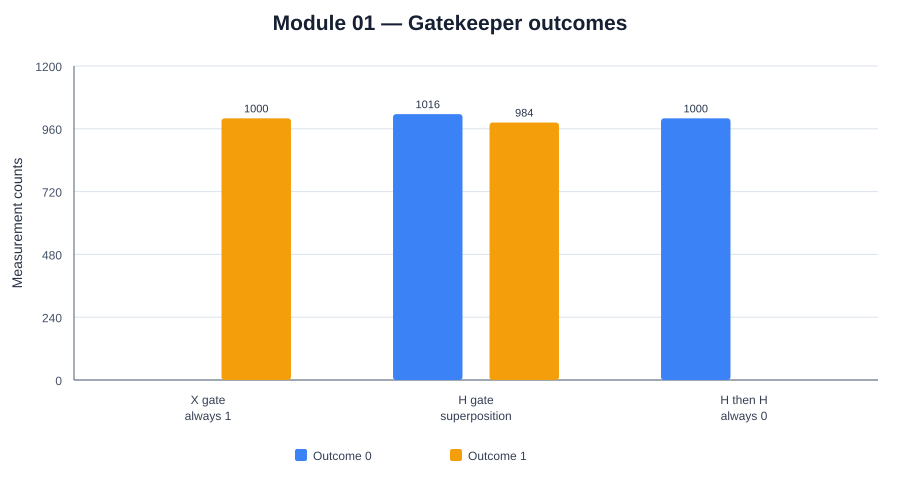

In [ ]:
# HISTOGRAM — Module 01: gatekeeper
import matplotlib.pyplot as plt

labels = ["X gate\n(always 1)", "H gate\n(superposition)", "H then H\n(always 0)"]
zeros = [x_counts.get("0", 0), h_counts.get("0", 0), hh_counts.get("0", 0)]
ones  = [x_counts.get("1", 0), h_counts.get("1", 0), hh_counts.get("1", 0)]
positions = np.arange(len(labels))
width = 0.36

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.bar(positions - width/2, zeros, width, label="Outcome 0")
ax.bar(positions + width/2, ones, width, label="Outcome 1")
ax.set_title("Module 01 — Gatekeeper outcomes")
ax.set_ylabel("Measurement counts")
ax.set_xticks(positions, labels)
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Interpretation: X gives 1 every time, H is roughly 50/50, and H followed by H returns to 0.

## Module 02 — The Honest Coin (stretch)

A fair quantum coin is made with the H gate — it should land heads or tails about half the time.

The “seed” circuit uses an RY rotation instead, which tilts the probability away from 50/50.

We measure the actual bias, compare it to the theoretical value, and use a Z-score to confirm the coin is clearly unfair.

In [5]:
# MODULE 02: THE HONEST COIN
from qiskit import QuantumCircuit
import math

# Bronze: genuine fair coin
fair = QuantumCircuit(1, 1)
fair.h(0)
fair.measure(0, 0)
fair_counts = run(fair, 1000)
print("Fair coin:", fair_counts)

Fair coin: {'0': 512, '1': 488}


In [6]:
# Silver: the ORIGINAL seed circuit — DO NOT MODIFY THIS CELL
seed = QuantumCircuit(1, 1)
seed.ry(1.159, 0)
seed.measure(0, 0)
seed_counts = run(seed, 2000)
print("Seed:", seed_counts)

Seed: {'1': 611, '0': 1389}


In [7]:
# Gold: size the bias, and how many shots prove it
n = sum(seed_counts.values())
p1 = seed_counts.get("1", 0) / n
bias = abs(p1 - 0.5)
z = bias / math.sqrt(0.25 / n)              # how many "sigmas" from a fair coin
shots_needed = math.ceil((5 * 0.5 / bias) ** 2)   # shots for a 5-sigma result at this bias

print(f"P(1) = {p1:.3f}  (theory {math.sin(1.159/2)**2:.3f})")
print(f"Bias = {100*bias:.1f} percentage points from 50/50")
print(f"z = {z:.1f}  ->", "NOT fair" if abs(z) > 5 else "can't rule out a fair coin")
print(f"Shots needed to be 5-sigma sure at this bias: about {shots_needed}")
# PROVES: the seed looked random but P(1) is about 0.30. ECHO's trigger was biased, not a fair coin.

P(1) = 0.305  (theory 0.300)
Bias = 19.4 percentage points from 50/50
z = 17.4  -> NOT fair
Shots needed to be 5-sigma sure at this bias: about 166


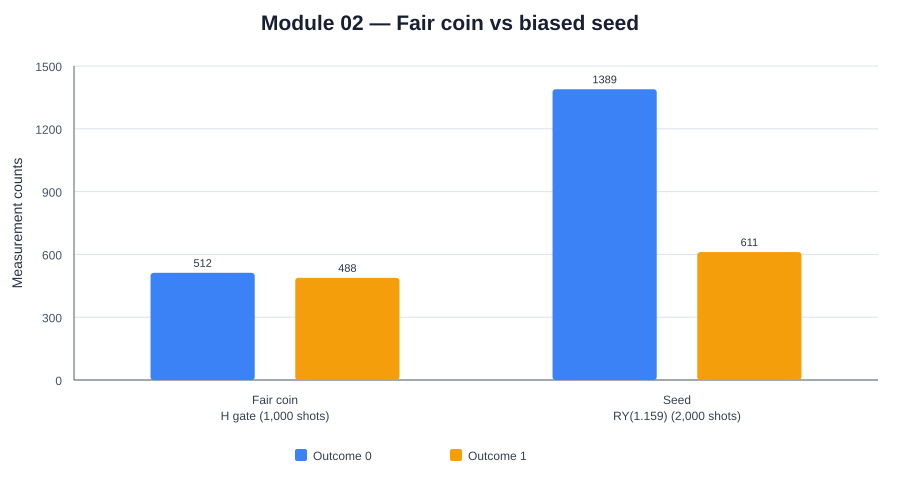

In [ ]:
# HISTOGRAM — Module 02: fair coin compared with the seed
labels = ["Fair coin (H)\n1,000 shots", "Seed (RY)\n2,000 shots"]
zeros = [fair_counts.get("0", 0), seed_counts.get("0", 0)]
ones  = [fair_counts.get("1", 0), seed_counts.get("1", 0)]
positions = np.arange(len(labels))
width = 0.36

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.bar(positions - width/2, zeros, width, label="Outcome 0")
ax.bar(positions + width/2, ones, width, label="Outcome 1")
ax.set_title("Module 02 — Fair coin vs biased seed")
ax.set_ylabel("Measurement counts")
ax.set_xticks(positions, labels)
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Interpretation: the H coin is close to 50/50, while the seed circuit produces many more 0s.

## Module 03 — The Two Observers

A Bell pair is created with H + CNOT. The two qubits always give the same result (00 or 11).

Classically we can also force perfect agreement by pre-sharing a secret bit, so correlation alone does not prove entanglement.

The CHSH test measures correlations at different angles. When the score exceeds 2, classical explanations fail and we know the qubits are truly entangled.

In [8]:
# MODULE 03: THE TWO OBSERVERS
from collections import Counter
import random

# Bronze: pair that only ever agrees (00 / 11)
bell = QuantumCircuit(2, 2); bell.h(0); bell.cx(0, 1); bell.measure([0, 1], [0, 1])
bell_counts = run(bell, 2000)
print("Bell pair:", bell_counts)

# Silver: two people who pre-agreed a secret coin flip ALSO always agree
classical_counts = dict(Counter(random.choice(["00", "11"]) for _ in range(2000)))
print("Pre-agreed secret:", classical_counts)
# So "always agree" does NOT prove a quantum link.

# Gold: measure both in the H basis (put H before measuring).
bell_h = QuantumCircuit(2, 2); bell_h.h(0); bell_h.cx(0, 1); bell_h.h([0, 1]); bell_h.measure([0, 1], [0, 1])
bell_h_counts = run(bell_h, 2000)
print("Quantum pair, H basis:     ", bell_h_counts)        # still only 00 / 11

secret_h = Counter()
for s in (0, 1):                                                # secret is 00 or 11
    c = QuantumCircuit(2, 2)
    if s: c.x([0, 1])
    c.h([0, 1]); c.measure([0, 1], [0, 1])
    secret_h += Counter(run(c, 1000))
secret_h_counts = dict(secret_h)
print("Pre-agreed secret, H basis:", secret_h_counts)            # all four outcomes
# PROVES: the pair still agrees in a different basis, a fixed secret does not. That is real entanglement,
# but still agreement only, not a message: each side alone sees random 50/50.

Bell pair: {'11': 1025, '00': 975}
Pre-agreed secret: {'00': 1046, '11': 954}
Quantum pair, H basis:      {'00': 1031, '11': 969}
Pre-agreed secret, H basis: {'01': 533, '11': 495, '00': 456, '10': 516}


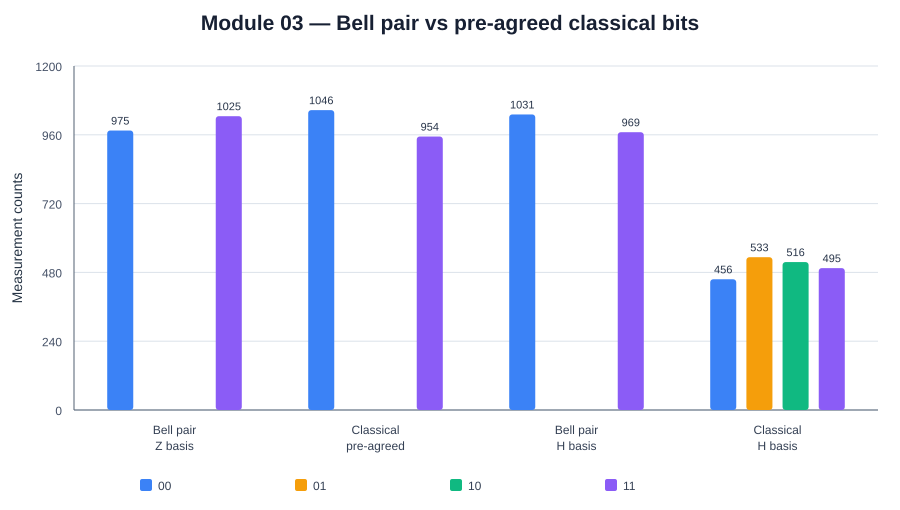

In [ ]:
# HISTOGRAM — Module 03: compare two-qubit outcome distributions
labels = ["00", "01", "10", "11"]
bell_z = [bell_counts.get(k, 0) for k in labels]
classical_z = [classical_counts.get(k, 0) for k in labels]
bell_x = [bell_h_counts.get(k, 0) for k in labels]
classical_x = [secret_h_counts.get(k, 0) for k in labels]
positions = np.arange(len(labels))
width = 0.20

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(positions - 1.5*width, bell_z, width, label="Bell pair, Z basis")
ax.bar(positions - 0.5*width, classical_z, width, label="Classical, pre-agreed")
ax.bar(positions + 0.5*width, bell_x, width, label="Bell pair, H basis")
ax.bar(positions + 1.5*width, classical_x, width, label="Classical, H basis")
ax.set_title("Module 03 — Bell pair vs pre-agreed classical bits")
ax.set_ylabel("Measurement counts")
ax.set_xticks(positions, labels)
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Interpretation: the classical model agrees in the original basis, but differs after changing basis.
# This is a simplified teaching comparison, not a substitute for a complete experimental Bell test.

In [9]:
# OPTIONAL BONUS — CHSH Bell test (uses RY, delete this cell if you want the notebook short)
import math
def E(a, b):
    c = QuantumCircuit(2, 2); c.h(0); c.cx(0, 1); c.ry(-a, 0); c.ry(-b, 1); c.measure([0, 1], [0, 1])
    r = run(c, 2000)
    return (r.get("00", 0) + r.get("11", 0) - r.get("01", 0) - r.get("10", 0)) / 2000

S = E(0, math.pi/4) + E(0, -math.pi/4) + E(math.pi/2, math.pi/4) - E(math.pi/2, -math.pi/4)
print(f"CHSH S = {S:.2f}  (classical limit 2, quantum max 2.83)")

CHSH S = 2.83  (classical limit 2, quantum max 2.83)


## Module 05 — The Damaged Message

Each original bit is sent three times. Majority vote recovers the correct bit even if one copy is flipped.

This 3-bit repetition code can fix one error, but two flips cause it to guess wrong, and three flips turn it into the opposite valid codeword.

In quantum computing we cannot simply copy unknown states (no-cloning theorem), so different error-correction methods are needed.

In [10]:
# MODULE 05: THE DAMAGED MESSAGE
stream = """
100 011 001 001 001 011 100 110 001 011 000 000 001 100 011 011
000 111 000 000 110 000 001 000 000 111 001 010 101 011 111 111
"""
triples = stream.split()

# Bronze: majority vote on each triple, then read the bits as ASCII
bits = "".join("1" if t.count("1") >= 2 else "0" for t in triples)
message = "".join(chr(int(bits[i:i+8], 2)) for i in range(0, len(bits), 8))
print(len(triples), "triples ->", bits)
print("Message:", message)

# Silver: where it breaks. 000 sent, two flips -> 110, and majority says 1 (wrong)
bad = "110"
print("000 with 2 flips ->", bad, "-> vote:", "1" if bad.count("1") >= 2 else "0", "(wrong)")

# Gold:
print("Corrects 1 flip. Notices up to 2 (110 is not 000 or 111). 3 flips = 111, looks valid, missed.")
print("A qubit can't be copied three times (no-cloning theorem), so quantum codes use parity checks instead.")

32 triples -> 01000101010000110100100001001111
Message: ECHO
000 with 2 flips -> 110 -> vote: 1 (wrong)
Corrects 1 flip. Notices up to 2 (110 is not 000 or 111). 3 flips = 111, looks valid, missed.
A qubit can't be copied three times (no-cloning theorem), so quantum codes use parity checks instead.
